In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.dummy import DummyRegressor, DummyClassifier

In [45]:
X_train = pd.read_csv("../03.results/outputs/X_train.csv")
y_train = pd.read_csv("../03.results/outputs/y_train.csv")
y_reg = y_train["target_next_return"]
y_clf = y_train["target_direction"]
print(X_train.shape, y_train.shape)

(1787, 40) (1787, 4)


In [46]:
import os
# delete this file (../03.results/logs/model_comparison.csv) if it exists to avoid appending to an old file
if os.path.exists("../03.results/logs/model_comparison.csv"):
    os.remove("../03.results/logs/model_comparison.csv")

In [47]:
from pathlib import Path

files = sorted(Path("../03.results/logs").glob("*.csv"))
print([f.name for f in files])

res = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
res.shape

['model_results_decision_tree.csv', 'model_results_knn.csv', 'model_results_logistic_regression.csv', 'model_results_polynomial.csv', 'model_results_random_forest.csv', 'model_results_ridge_lasso.csv', 'model_results_svm.csv', 'model_results_svm_tuned.csv', 'model_results_xgboost.csv']


(16, 14)

9 model names appear: 6 with both tasks, Ridge/Lasso/Polynomial regression-only, Logistic classification-only.

In [48]:
tscv = TimeSeriesSplit(n_splits=5)
REG_SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}
CLF_SCORING = {"accuracy": "accuracy", "f1": "f1", "roc_auc": "roc_auc"}
def cv_scores(model, y, task):
    scoring = REG_SCORING if task == "regression" else CLF_SCORING
    r = cross_validate(model, X_train, y, cv=tscv, scoring=scoring)
    out = {"task": task}
    for k in scoring:
        v = r[f"test_{k}"]; v = -v if k in ("rmse", "mae") else v
        out[k] = v.mean(); out[k + "_std"] = v.std()
    return out
base = pd.DataFrame([
    {"model": "BASELINE predict 0", **cv_scores(DummyRegressor(strategy="constant", constant=0.0), y_reg, "regression")},
    {"model": "BASELINE predict mean", **cv_scores(DummyRegressor(strategy="mean"), y_reg, "regression")},
    {"model": "BASELINE majority/prior", **cv_scores(DummyClassifier(strategy="prior"), y_clf, "classification")}])
table = pd.concat([res, base], ignore_index=True)

In [49]:
cls = table[table.task == "classification"].sort_values("roc_auc", ascending=False)
reg = table[table.task == "regression"].sort_values("rmse")
print(cls[["model", "accuracy", "roc_auc", "roc_auc_std"]].round(4).to_string(index=False))
print(reg[["model", "rmse", "rmse_std", "r2", "mae"]].round(5).to_string(index=False))

                  model  accuracy  roc_auc  roc_auc_std
              SVM_Tuned    0.5104   0.5303       0.0303
          Random Forest    0.5172   0.5249       0.0218
                XGBoost    0.5138   0.5168       0.0267
                    SVM    0.5091   0.5135       0.0258
          Decision Tree    0.5084   0.5129       0.0240
                    KNN    0.4889   0.5084       0.0176
    Logistic Regression    0.5084   0.5069       0.0486
BASELINE majority/prior    0.4896   0.5000       0.0000
                model    rmse  rmse_std       r2     mae
   BASELINE predict 0 0.04929   0.01461 -0.00172 0.03624
BASELINE predict mean 0.04941   0.01449 -0.00871 0.03636
                Ridge 0.04957   0.01495 -0.00989 0.03653
        Random Forest 0.04983   0.01500 -0.02073 0.03661
            SVM_Tuned 0.05012   0.01444 -0.04119 0.03701
                  KNN 0.05030   0.01472 -0.04587 0.03698
              XGBoost 0.05162   0.01683 -0.08504 0.03779
Polynomial Regression 0.05264   0.01850 

Most models sit within noise of the baselines. That is the one of finding of this stage.

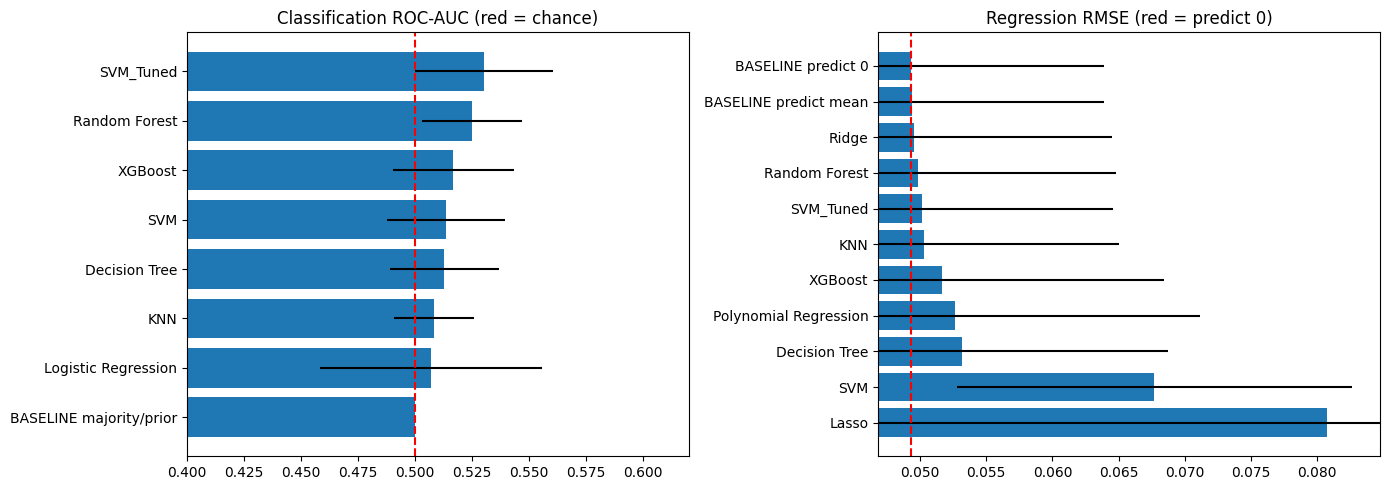

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
c = cls.iloc[::-1]; ax[0].barh(c.model, c.roc_auc, xerr=c.roc_auc_std); ax[0].axvline(0.5, color="r", ls="--"); ax[0].set_xlim(0.4, 0.62); ax[0].set_title("Classification ROC-AUC (red = chance)")
r = reg.iloc[::-1]; ax[1].barh(r.model, r.rmse, xerr=r.rmse_std); ax[1].axvline(r[r.model == "BASELINE predict 0"].rmse.iloc[0], color="r", ls="--")
ax[1].set_xlim(r.rmse.min() * 0.95, r.rmse.max() * 1.05); ax[1].set_title("Regression RMSE (red = predict 0)")
plt.tight_layout(); fig.savefig("../03.results/eda_visualizations/model_comparison.png", dpi=130); plt.show()

In [51]:
real_cls = cls[~cls.model.str.startswith("BASELINE")]; real_reg = reg[~reg.model.str.startswith("BASELINE")]
selected = {"classification": {"top": real_cls.model.head(2).tolist()}, "regression": {"top": real_reg.model.head(2).tolist()}}
table.round(6).to_csv("../03.results/logs/model_comparison.csv", index=False)
print(selected)

{'classification': {'top': ['SVM_Tuned', 'Random Forest']}, 'regression': {'top': ['Ridge', 'Random Forest']}}
